Exercises:
- **E01: I did not get around to seeing what happens when you initialize all weights and biases to zero. Try this and train the neural net. You might think either that 1) the network trains just fine or 2) the network doesn't train at all, but actually it is 3) the network trains but only partially, and achieves a pretty bad final performance. Inspect the gradients and activations to figure out what is happening and why the network is only partially training, and what part is being trained exactly.**
- E02: BatchNorm, unlike other normalization layers like LayerNorm/GroupNorm etc. has the big advantage that after training, the batchnorm gamma/beta can be "folded into" the weights of the preceeding Linear layers, effectively erasing the need to forward it at test time. Set up a small 3-layer MLP with batchnorms, train the network, then "fold" the batchnorm gamma/beta into the preceeding Linear layer's W,b by creating a new W2, b2 and erasing the batch norm. Verify that this gives the same forward pass during inference. i.e. we see that the batchnorm is there just for stabilizing the training, and can be thrown out after training is done! pretty cool.

In [5]:
import ctypes
from pathlib import Path

# On this host, load the native NVIDIA driver before PyTorch's CUDA compatibility library.
native_driver = Path("/usr/lib/x86_64-linux-gnu/libcuda.so.1")
if native_driver.is_file():
  ctypes.CDLL(str(native_driver), mode=ctypes.RTLD_GLOBAL)

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

device = torch.device("cuda")
try:
  gpu_name = torch.cuda.get_device_name(device)
except RuntimeError as error:
  if "Error 804" in str(error):
    raise RuntimeError("This kernel already loaded the CUDA compatibility driver. Click Restart Kernel in the notebook toolbar, then run this first cell. The NN (CUDA) Jupyter kernel also loads the system NVIDIA driver at startup.") from None
  raise
print(f"Training on {device}: {gpu_name}")

Training on cuda: NVIDIA GeForce RTX 3090


In [6]:
# read in all the words
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [7]:
len(words)

32033

In [8]:
# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
vocab_size = len(itos)
print(itos)
print(vocab_size)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}
27


In [9]:
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):  
  X, Y = [], []
  
  for w in words:
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X, device=device)
  Y = torch.tensor(Y, device=device)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr,  Ytr  = build_dataset(words[:n1])     # 80%
Xdev, Ydev = build_dataset(words[n1:n2])   # 10%
Xte,  Yte  = build_dataset(words[n2:])     # 10%


torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [10]:
# Let's train a deeper network
# The classes we create here are the same API as nn.Module in PyTorch

class Linear:
  
  def __init__(self, fan_in, fan_out, bias=True):
    # self.weight = torch.randn((fan_in, fan_out), generator=train_generator, device=device) / fan_in**0.5
    self.weight = torch.zeros((fan_in, fan_out), device=device)
    self.bias = torch.zeros(fan_out, device=device) if bias else None
  
  def __call__(self, x):
    self.out = x @ self.weight
    if self.bias is not None:
      self.out += self.bias
    return self.out
  
  def parameters(self):
    return [self.weight] + ([] if self.bias is None else [self.bias])


class BatchNorm1d:
  
  def __init__(self, dim, eps=1e-5, momentum=0.1):
    self.eps = eps
    self.momentum = momentum
    self.training = True
    # parameters (trained with backprop)
    self.gamma = torch.ones(dim, device=device)
    self.beta = torch.zeros(dim, device=device)
    # buffers (trained with a running 'momentum update')
    self.running_mean = torch.zeros(dim, device=device)
    self.running_var = torch.ones(dim, device=device)
  
  def __call__(self, x):
    # calculate the forward pass
    if self.training:
      xmean = x.mean(0, keepdim=True) # batch mean
      xvar = x.var(0, keepdim=True) # batch variance
    else:
      xmean = self.running_mean
      xvar = self.running_var
    xhat = (x - xmean) / torch.sqrt(xvar + self.eps) # normalize to unit variance
    self.out = self.gamma * xhat + self.beta
    # Update the same buffers across CUDA Graph replays.
    if self.training:
      with torch.no_grad():
        self.running_mean.lerp_(xmean.squeeze(0), self.momentum)
        self.running_var.lerp_(xvar.squeeze(0), self.momentum)
    return self.out
  
  def parameters(self):
    return [self.gamma, self.beta]

class Tanh:
  def __call__(self, x):
    self.out = torch.tanh(x)
    return self.out
  def parameters(self):
    return []

n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 100 # the number of neurons in the hidden layer of the MLP
train_generator = torch.Generator(device=device).manual_seed(2147483647) # for reproducibility

C = torch.randn((vocab_size, n_embd), generator=train_generator, device=device)
layers = [
  Linear(n_embd * block_size, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
  Linear(           n_hidden, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
  Linear(           n_hidden, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
  Linear(           n_hidden, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
  Linear(           n_hidden, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
  Linear(           n_hidden, vocab_size, bias=False), BatchNorm1d(vocab_size),
]
# layers = [
#   Linear(n_embd * block_size, n_hidden), Tanh(),
#   Linear(           n_hidden, n_hidden), Tanh(),
#   Linear(           n_hidden, n_hidden), Tanh(),
#   Linear(           n_hidden, n_hidden), Tanh(),
#   Linear(           n_hidden, n_hidden), Tanh(),
#   Linear(           n_hidden, vocab_size),
# ]

with torch.no_grad():
  # last layer: make less confident
  layers[-1].gamma *= 0.1
  # layers[-1].weight *= 0.1
  # all other layers: apply gain
  for layer in layers[:-1]:
    if isinstance(layer, Linear):
      layer.weight *= 1.0 #5/3

parameters = [C] + [p for layer in layers for p in layer.parameters()]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.requires_grad = True

47024


In [11]:
# SGD training
max_steps = 200000
batch_size = 32


def train_model(max_steps, batch_size):
  loss_history = torch.empty(max_steps, device=device)
  update_history = torch.empty((max_steps, len(parameters)), device=device)
  step_index = torch.zeros(1, dtype=torch.long, device=device)

  for layer in layers:
    layer.training = True

  def train_step():
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=train_generator, device=device)
    emb = C[Xtr[ix]]
    x = emb.flatten(1)
    for layer in layers:
      x = layer(x)
    loss = F.cross_entropy(x, Ytr[ix])

    for layer in layers:
      layer.out.retain_grad()
    for p in parameters:
      p.grad = None
    loss.backward()

    with torch.no_grad():
      lr = torch.where(step_index < 150000, 0.1, 0.01)
      for p in parameters:
        p.addcmul_(p.grad, lr, value=-1.0)

      ratios = torch.stack([p.grad.std() / p.std() for p in parameters])
      loss_history.index_copy_(0, step_index, loss.log10().reshape(1))
      update_history.index_copy_(0, step_index, (lr * ratios).log10().unsqueeze(0))
      step_index.add_(1)

  # Warm up the CUDA kernels on a side stream, counting these as training steps.
  warmup_steps = min(3, max_steps)
  warmup_stream = torch.cuda.Stream(device=device)
  current_stream = torch.cuda.current_stream(device)
  warmup_stream.wait_stream(current_stream)
  with torch.cuda.stream(warmup_stream):
    for _ in range(warmup_steps):
      train_step()
  current_stream.wait_stream(warmup_stream)

  if max_steps:
    print(f'{0:7d}/{max_steps:7d}: {10.0 ** loss_history[0].item():.4f}')
  if max_steps > warmup_steps:
    # Capture one fixed-size minibatch step to reuse its CUDA kernel launches.
    graph = torch.cuda.CUDAGraph()
    graph.register_generator_state(train_generator)
    with torch.cuda.graph(graph):
      train_step()
    for i in range(warmup_steps, max_steps):
      graph.replay()
      if i % 10000 == 0:
        print(f'{i:7d}/{max_steps:7d}: {10.0 ** loss_history[i].item():.4f}')

  return loss_history.cpu(), update_history.cpu()


lossi, ud = train_model(max_steps, batch_size)

# Subsequent evaluation and sampling overwrite layer.out.
tanh_diagnostics = [
  (i, layer.out.detach().cpu(), layer.out.grad.detach().cpu())
  for i, layer in enumerate(layers)
  if isinstance(layer, Tanh)
]

      0/ 200000: 3.2958
  10000/ 200000: 2.6981
  20000/ 200000: 2.4130
  30000/ 200000: 2.6200
  40000/ 200000: 2.7879
  50000/ 200000: 2.8370
  60000/ 200000: 3.1608
  70000/ 200000: 3.0475
  80000/ 200000: 3.1032
  90000/ 200000: 2.6899
 100000/ 200000: 2.6284
 110000/ 200000: 2.8209
 120000/ 200000: 2.7135
 130000/ 200000: 2.8527
 140000/ 200000: 3.0948
 150000/ 200000: 2.8891
 160000/ 200000: 2.9129
 170000/ 200000: 2.9201
 180000/ 200000: 2.8119
 190000/ 200000: 2.5513


layer 2 (Tanh): mean +0.00, std 0.00, saturated: 0.00%
layer 5 (Tanh): mean +0.00, std 0.00, saturated: 0.00%
layer 8 (Tanh): mean +0.00, std 0.00, saturated: 0.00%
layer 11 (Tanh): mean +0.00, std 0.00, saturated: 0.00%
layer 14 (Tanh): mean +0.00, std 0.00, saturated: 0.00%


Text(0.5, 1.0, 'activation distribution')

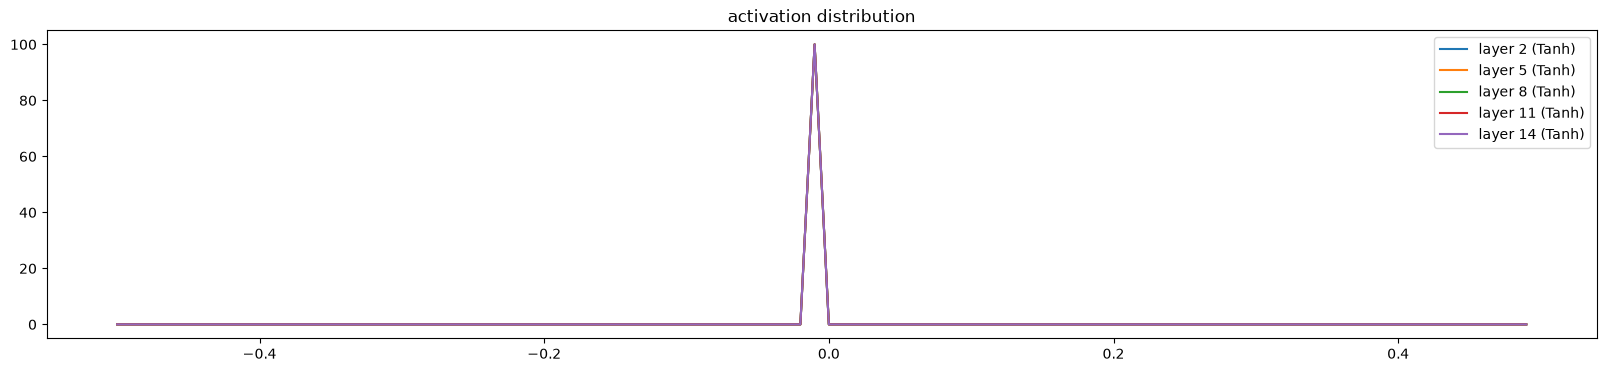

In [12]:
# visualize histograms
plt.figure(figsize=(20, 4))
for i, t, _ in tanh_diagnostics:
  print('layer %d (Tanh): mean %+.2f, std %.2f, saturated: %.2f%%' % (i, t.mean(), t.std(), (t.abs() > 0.97).float().mean() * 100))
  hy, hx = torch.histogram(t, density=True)
  plt.plot(hx[:-1], hy, label=f'layer {i} (Tanh)')
plt.legend()
plt.title('activation distribution')

layer 2 (Tanh): mean +0.000000, std 0.000000e+00
layer 5 (Tanh): mean +0.000000, std 0.000000e+00
layer 8 (Tanh): mean +0.000000, std 0.000000e+00
layer 11 (Tanh): mean +0.000000, std 0.000000e+00
layer 14 (Tanh): mean +0.000000, std 0.000000e+00


Text(0.5, 1.0, 'gradient distribution')

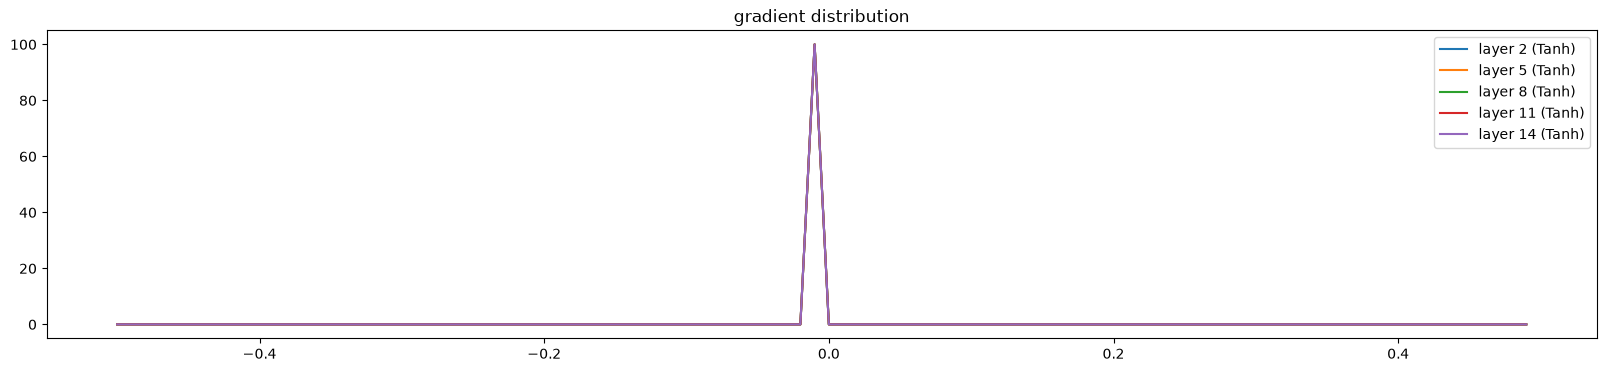

In [13]:
# visualize histograms
plt.figure(figsize=(20, 4))
for i, _, t in tanh_diagnostics:
  print('layer %d (Tanh): mean %+f, std %e' % (i, t.mean(), t.std()))
  hy, hx = torch.histogram(t, density=True)
  plt.plot(hx[:-1], hy, label=f'layer {i} (Tanh)')
plt.legend()
plt.title('gradient distribution')

weight   (27, 10) | mean +0.000000 | std 0.000000e+00 | grad:data ratio 0.000000e+00
weight  (30, 100) | mean +0.000000 | std 0.000000e+00 | grad:data ratio nan
weight (100, 100) | mean +0.000000 | std 0.000000e+00 | grad:data ratio nan
weight (100, 100) | mean +0.000000 | std 0.000000e+00 | grad:data ratio nan
weight (100, 100) | mean +0.000000 | std 0.000000e+00 | grad:data ratio nan
weight (100, 100) | mean +0.000000 | std 0.000000e+00 | grad:data ratio nan
weight  (100, 27) | mean +0.000000 | std 0.000000e+00 | grad:data ratio nan


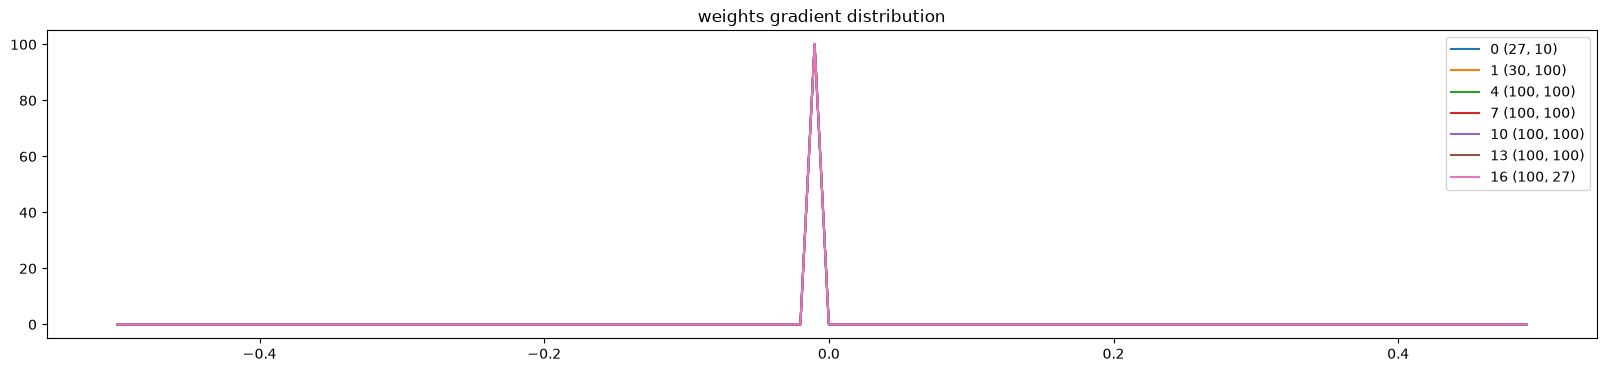

In [14]:
# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i,p in enumerate(parameters):
  if p.ndim == 2:
    t = p.grad.detach().cpu()
    print('weight %10s | mean %+f | std %e | grad:data ratio %e' % (tuple(p.shape), t.mean(), t.std(), t.std() / p.detach().std().item()))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'{i} {tuple(p.shape)}')
plt.legend(legends)
plt.title('weights gradient distribution');

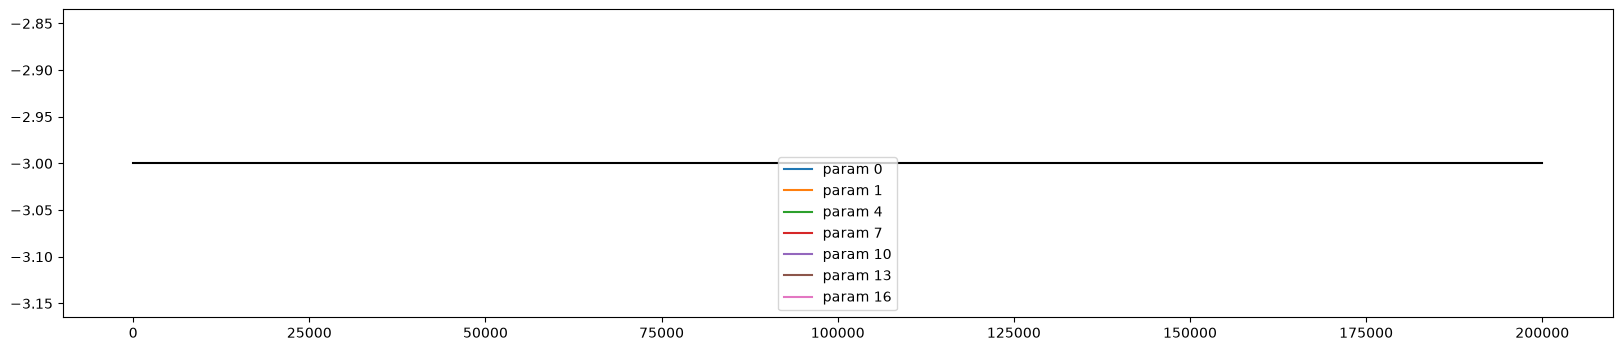

In [15]:
plt.figure(figsize=(20, 4))
legends = []
for i,p in enumerate(parameters):
  if p.ndim == 2:
    plt.plot(ud[:, i])
    legends.append('param %d' % i)
plt.plot([0, len(ud)], [-3, -3], 'k') # these ratios should be ~1e-3, indicate on plot
plt.legend(legends);


In [16]:
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(split):
  x,y = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xte, Yte),
  }[split]
  loss_sum = torch.zeros((), device=device)
  for contexts, targets in zip(x.split(4096), y.split(4096)):
    features = C[contexts].flatten(1)
    for layer in layers:
      features = layer(features)
    loss_sum += F.cross_entropy(features, targets, reduction='sum')
  print(split, (loss_sum / len(y)).item())

# put layers into eval mode
for layer in layers:
  layer.training = False
split_loss('train')
split_loss('val')

train 2.822650671005249
val 2.8210628032684326


In [17]:
# sample from the model
sample_generator = torch.Generator(device=device).manual_seed(2147483647 + 10)
for layer in layers:
  layer.training = False

with torch.no_grad():
  for _ in range(20):
    
      out = []
      context = [0] * block_size # initialize with all ...
      while True:
        # forward pass the neural net
        emb = C[torch.tensor([context], device=device)] # (1,block_size,n_embd)
        x = emb.view(emb.shape[0], -1) # concatenate the vectors
        for layer in layers:
          x = layer(x)
        logits = x
        probs = F.softmax(logits, dim=1)
        # sample from the distribution
        ix = torch.multinomial(probs, num_samples=1, generator=sample_generator).item()
        # shift the context window and track the samples
        context = context[1:] + [ix]
        out.append(ix)
        # if we sample the special '.' token, break
        if ix == 0:
          break
    
      print(''.join(itos[i] for i in out)) # decode and print the generated word

bnkitsyhyznmndr.
rylmjrnh.
rdrsneyb.
lidzjomurahheca.
rmygtp.
dgewey.
icifnmetnt.
.
eloohi.
arstttatj.
endheidykavr.
hraan.
a.
ilana.
uoina.
ari.
i.
vhihek.
okasaadlsvcigpbg.
nncxc.


In [ ]:
# DONE; BONUS content below, not covered in video

interactive(children=(FloatSlider(value=0.0, description='x0', max=30.0, min=-30.0, step=0.5), Output()), _dom…

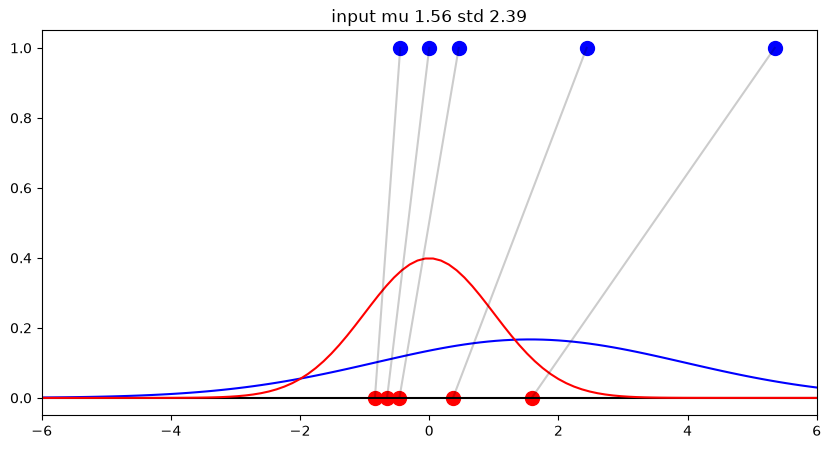

In [21]:
# BatchNorm forward pass as a widget

from ipywidgets import interact, interactive, fixed, interact_manual
import ipywidgets as widgets
import scipy.stats as stats
import numpy as np

def normshow(x0):
  
  g = torch.Generator().manual_seed(2147483647+1)
  x = torch.randn(5, generator=g) * 5
  x[0] = x0 # override the 0th example with the slider
  mu = x.mean()
  sig = x.std()
  y = (x - mu)/sig

  plt.figure(figsize=(10, 5))
  # plot 0
  plt.plot([-6,6], [0,0], 'k')
  # plot the mean and std
  xx = np.linspace(-6, 6, 100)
  plt.plot(xx, stats.norm.pdf(xx, mu, sig), 'b')
  xx = np.linspace(-6, 6, 100)
  plt.plot(xx, stats.norm.pdf(xx, 0, 1), 'r')
  # plot little lines connecting input and output
  for i in range(len(x)):
    plt.plot([x[i],y[i]], [1, 0], 'k', alpha=0.2)
  # plot the input and output values
  plt.scatter(x.data, torch.ones_like(x).data, c='b', s=100)
  plt.scatter(y.data, torch.zeros_like(y).data, c='r', s=100)
  plt.xlim(-6, 6)
  # title
  plt.title('input mu %.2f std %.2f' % (mu, sig))

interact(normshow, x0=(-30,30,0.5));


In [20]:
# Linear: activation statistics of forward and backward pass

g = torch.Generator().manual_seed(2147483647)

a = torch.randn((1000,1), requires_grad=True, generator=g)          # a.grad = b.T @ c.grad
b = torch.randn((1000,1000), requires_grad=True, generator=g)       # b.grad = c.grad @ a.T
c = b @ a
loss = torch.randn(1000, generator=g) @ c
a.retain_grad()
b.retain_grad()
c.retain_grad()
loss.backward()
print('a std:', a.std().item())
print('b std:', b.std().item())
print('c std:', c.std().item())
print('-----')
print('c grad std:', c.grad.std().item())
print('a grad std:', a.grad.std().item())
print('b grad std:', b.grad.std().item())

a std: 0.9875972270965576
b std: 1.0006722211837769
c std: 31.01241683959961
-----
c grad std: 0.9782556295394897
a grad std: 30.8818302154541
b grad std: 0.9666601419448853


**全零初始化后，模型只学到了输出端的偏置。** 在这份 notebook 里，最后一个 `Linear` 设置了 `bias=False`，因此实际更新的是**最后一个 BatchNorm 的 `beta`**。

**前向传播时**，全零权重让每个隐藏层的 Linear 输出为 0。隐藏层 BatchNorm 的 `beta` 初始也为 0，接着 `tanh(0)=0`。这就是为什么激活图里五层都堆在 0，标准差和饱和率也都是 0。

**反向传播时**，用最后一个 Linear 就能解释两张梯度图。设它的输入为 $h$、权重为 $W$、输出为 $z=hW$，从输出端传来的梯度为 $G=\partial L/\partial z$。那么：

$$
\frac{\partial L}{\partial W}=h^\top G=0,\qquad
\frac{\partial L}{\partial h}=GW^\top=0.
$$

第一式因为 $h=0$，最后一层权重的更新量为零。第二式因为 $W=0$，传回前面隐藏层的梯度也为零。Tanh 在 0 处的导数是 **1**，这里的零梯度来自乘上了全零权重。每一步都重复这个过程。

**最后的 `beta` 能学，是因为它直接加到 logits 上。** 对字符 $k$，它的梯度是模型给出的概率 $p_k$ 减去该字符在当前批次目标中的频率。训练因此能把常见字符的概率调高，但所有上下文仍共享同一组概率 $p=\operatorname{softmax}(\beta)$。

这次把所有 Linear 权重置零，跑完 20 万步后，验证 loss 为 **2.82106**。直接按训练集的字符频率预测，验证 loss 为 **2.82102**。这说明 loss 的改善来自学到了**字符的总体频率**。按题意把 Embedding `C` 和 BN 的 `gamma` 也置零，同样的推导仍然成立。